John S. Anvik, 2025  
University of Lethbridge Student ID: 001224816

Import Packages

In [1]:
# install.packages("tidymodels")
# install.packages('rlang')
# install.packages("ranger")
# install.packages("rpart.plot")
# install.packages("vip")
library(tidyverse)
library(tidymodels)
library(rpart.plot) # for plotting decision tree
library(vip) # for ranking feature importance
# library(ranger) # engine for random forest

# set random seed
set.seed(42)

Warning message:
"package 'tidyverse' was built under R version 4.4.3"
Warning message:
"package 'ggplot2' was built under R version 4.4.3"
Warning message:
"package 'tibble' was built under R version 4.4.3"
Warning message:
"package 'tidyr' was built under R version 4.4.3"
Warning message:
"package 'readr' was built under R version 4.4.3"
Warning message:
"package 'purrr' was built under R version 4.4.3"
Warning message:
"package 'dplyr' was built under R version 4.4.3"
Warning message:
"package 'forcats' was built under R version 4.4.3"
Warning message:
"package 'lubridate' was built under R version 4.4.3"
── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   4.0.0     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.1.0     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()

Load data

In [2]:
data <- read_csv("../data/matching_opportunities.csv") %>%
    drop_na() # drop any row containing at least one NA value

Rows: 709 Columns: 64
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl  (63): UST, time_rel_sunrise, D_M1_M2, D_M1_M3, D_M1_M4, D_M1_M5, D_M1_M...
dttm  (1): DateTime

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [3]:
# Model Inputs
model_columns <- c(
        "UST", 
        # "does_it_match",
        # "D_M1_M2", "D_M1_M3", "D_M1_M4", "D_M1_M5", "D_M1_M6",
        # "M1_last_UST", "M2_last_UST", "M3_last_UST", "M4_last_UST", "M5_last_UST", "M6_last_UST", # TODO: These are categorical variables, how does this implementation of knn handle those?
        "M1_1_last_UST", "M2_1_last_UST", "M3_1_last_UST", "M4_1_last_UST", "M5_1_last_UST", "M6_1_last_UST", 
        "M1_2_last_UST", "M2_2_last_UST", "M3_2_last_UST", "M4_2_last_UST", "M5_2_last_UST", "M6_2_last_UST", 
        # "time_M1_last_song", "time_M2_last_song", "time_M3_last_song", "time_M4_last_song", "time_M5_last_song", "time_M6_last_song",
    	"time_since_M1_1_last_song", "time_since_M2_1_last_song", "time_since_M3_1_last_song", "time_since_M4_1_last_song", "time_since_M5_1_last_song", "time_since_M6_1_last_song", # did not include time since M1 last song because it is always 0
    	"time_since_M1_2_last_song", "time_since_M2_2_last_song", "time_since_M3_2_last_song", "time_since_M4_2_last_song", "time_since_M5_2_last_song", "time_since_M6_2_last_song" # did not include time since M1 last song because it is always 0
        # "time_rel_sunrise"
    )

In [4]:
# Set data types and select input columns
data <- data %>% 
    mutate(across(contains("UST"), ~ as.factor(.x)), 
        does_it_match = as.factor(does_it_match),
        number_of_matches = as.integer(number_of_matches)) %>%
    select(model_columns)

Warning message:
"Using an external vector in selections was deprecated in tidyselect 1.1.0.
ℹ Please use `all_of()` or `any_of()` instead.
  # Was:
  data %>% select(model_columns)

  # Now:
  data %>% select(all_of(model_columns))

See <https://tidyselect.r-lib.org/reference/faq-external-vector.html>."


In [5]:
glimpse(data)

Rows: 426
Columns: 25
$ UST                       <fct> 3, 0, 13, 9, 8, 3, 116, 29, 10, 8, 3, 21, 5,…
$ M1_1_last_UST             <fct> 0, 3, 0, 29, 9, 8, 3, 116, 29, 10, 8, 3, 21,…
$ M2_1_last_UST             <fct> 8, 9, 0, 5, 16, 9, 3, 8, 8, 9, 3, 9, 16, 8, …
$ M3_1_last_UST             <fct> 8, 0, 0, 8, 8, 8, 8, 0, 8, 9, 3, 0, 16, 8, 0…
$ M4_1_last_UST             <fct> 9, 9, 0, 3, 3, 8, 8, 9, 9, 10, 10, 3, 0, 16,…
$ M5_1_last_UST             <fct> 8, 0, 0, 0, 8, 0, 0, 10, 10, 8, 8, 20, 20, 0…
$ M6_1_last_UST             <fct> 0, 0, 0, 8, 8, 8, 0, 0, 0, 0, 3, 0, 0, 0, 9,…
$ M1_2_last_UST             <fct> 0, 20, 0, 8, 29, 9, 8, 3, 116, 29, 10, 8, 3,…
$ M2_2_last_UST             <fct> 8, 3, 0, 0, 5, 16, 9, 3, 3, 8, 9, 3, 9, 16, …
$ M3_2_last_UST             <fct> 9, 3, 0, 9, 9, 9, 9, 9, 8, 8, 9, 3, 0, 16, 8…
$ M4_2_last_UST             <fct> 0, 3, 20, 9, 9, 3, 3, 8, 8, 9, 9, 10, 3, 0, …
$ M5_2_last_UST             <fct> 0, 0, 0, 0, 0, 8, 0, 0, 10, 10, 10, 0, 0, 20…
$ M6_2_last_UST   

In [6]:

# train test split
train_test_split <- initial_split(data, prop = 0.7, strata=UST)

train_data <- train_test_split %>% training()
test_data <- train_test_split %>% testing()

# In training data, how many song type matches?
train_data %>%
    group_by(UST) %>%
    summarize(n = n()) %>%
    mutate(percent = 100*n/nrow(train_data))

# use v-fold cross validation to assess model accuracy
v <- 5
train_vfold <- vfold_cv(train_data, v=v, strata = UST)

UST,n,percent
<fct>,<int>,<dbl>
0,5,1.6891892
3,45,15.2027027
5,20,6.7567568
8,46,15.5405405
9,41,13.8513514
10,30,10.1351351
12,2,0.6756757
13,19,6.4189189
16,1,0.3378378


In [7]:
# Data preprocessing using a recipe
recipe <- recipe(UST ~ ., data = train_data) %>%
    step_scale(all_numeric()) %>% # scale all numeric predictors
    step_center(all_numeric()) # center all numeric predictors

In [8]:
# Create model specification
model_tuning_spec <- rand_forest(mtry = tune(), trees = 1000, min_n=tune()) %>%
    set_engine("ranger", importance = "impurity") %>% # importance = impurity measures feature importance (using gini impurity reduction), used for vip() later
    set_mode("classification")

In [9]:
tune_grid <- tidyr::crossing(
    mtry = c(4, 8, 12, 16, 20), # The number of variables randomly sampled as candidates at each split
    min_n = c(2, 5, 10, 15, 20) # Minimum number of data points in a node required for a split
)
eval_metrics <- metric_set(accuracy, precision, recall)

model_tuning <- workflow() %>%
    add_recipe(recipe) %>%
    add_model(model_tuning_spec) %>%

        tune_grid(resamples = train_vfold, grid=tune_grid, metrics = eval_metrics) # for v-fold cross validation, tuning k parameter
        # fit(data = train_data) # to train on whole train set with no validation set

model_tuning

→ A | warning: Dropped unused factor level(s) in dependent variable: 116, 119.

There were issues with some computations   A: x1

There were issues with some computations   A: x10

There were issues with some computations   A: x28

There were issues with some computations   A: x55

There were issues with some computations   A: x78

There were issues with some computations   A: x120

There were issues with some computations   A: x153

There were issues with some computations   A: x190

There were issues with some computations   A: x231

There were issues with some computations   A: x253

There were issues with some computations   A: x300

→ B | warning: While computing multiclass `precision()`, some levels had no predicted events
               (i.e. `true_positive + false_positive = 0`).
               Precision is undefined in this case, and those levels will be removed from the
               averaged result.
               Note that the following number of true events actually occur

In [10]:
# Accuracies listed use 5-fold cross validation 2025-10-17
model_tuning_accuracies <- model_tuning %>% collect_metrics() %>% arrange(.metric) #  %>% filter(.metric == "accuracy")
model_tuning_accuracies

mtry,min_n,.metric,.estimator,mean,n,std_err,.config
<dbl>,<dbl>,<chr>,<chr>,<dbl>,<int>,<dbl>,<chr>
4,2,accuracy,multiclass,0.1654696,5,0.02075969,pre0_mod01_post0
4,5,accuracy,multiclass,0.1823133,5,0.01850362,pre0_mod02_post0
4,10,accuracy,multiclass,0.1790853,5,0.02482645,pre0_mod03_post0
4,15,accuracy,multiclass,0.1853599,5,0.01841502,pre0_mod04_post0
4,20,accuracy,multiclass,0.1858201,5,0.01585500,pre0_mod05_post0
8,2,accuracy,multiclass,0.1895610,5,0.02152736,pre0_mod06_post0
8,5,accuracy,multiclass,0.1761050,5,0.01821496,pre0_mod07_post0
8,10,accuracy,multiclass,0.1791458,5,0.02316038,pre0_mod08_post0
8,15,accuracy,multiclass,0.1762063,5,0.02607489,pre0_mod09_post0


Ignoring unknown labels:
• colour : "Estimated Accuracy"


[1] "Best hyperparameters: (mtry, min_n)"
 5 
12 


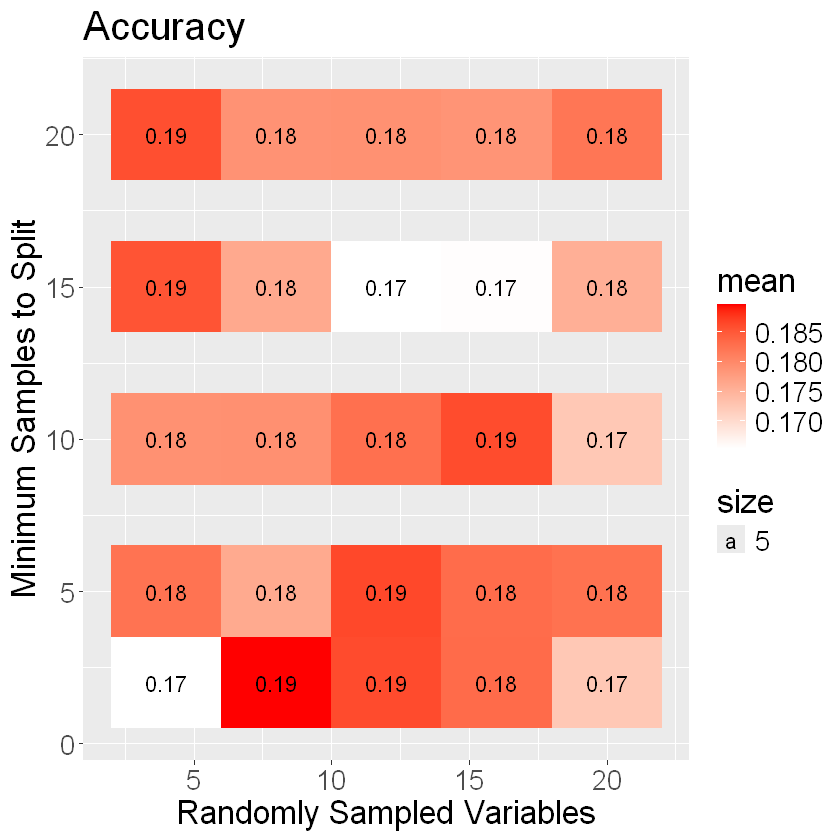

In [11]:
# plot accuracies of all values of hyperparameters

ggplot(model_tuning_accuracies %>% filter(.metric == "accuracy")) +
    geom_tile(aes(x=mtry, y=min_n, fill=mean)) +
    geom_text(aes(x=mtry, y=min_n, label=round(mean, 2), size=5)) +
    labs(x = "Randomly Sampled Variables", y = "Minimum Samples to Split", color="Estimated Accuracy", title="Accuracy") +
    theme(text = element_text(size=20)) +
    scale_fill_gradient(low="white", high="red")

# Print best hyperparameter values
best_params <- model_tuning_accuracies %>% arrange(desc(mean)) %>% head(1) %>% pull(mtry, min_n)
print("Best hyperparameters: (mtry, min_n)")
print(best_params)

Ignoring unknown labels:
• colour : "Estimated Recall"


[1] "Best hyperparameters:"
 5 
12 


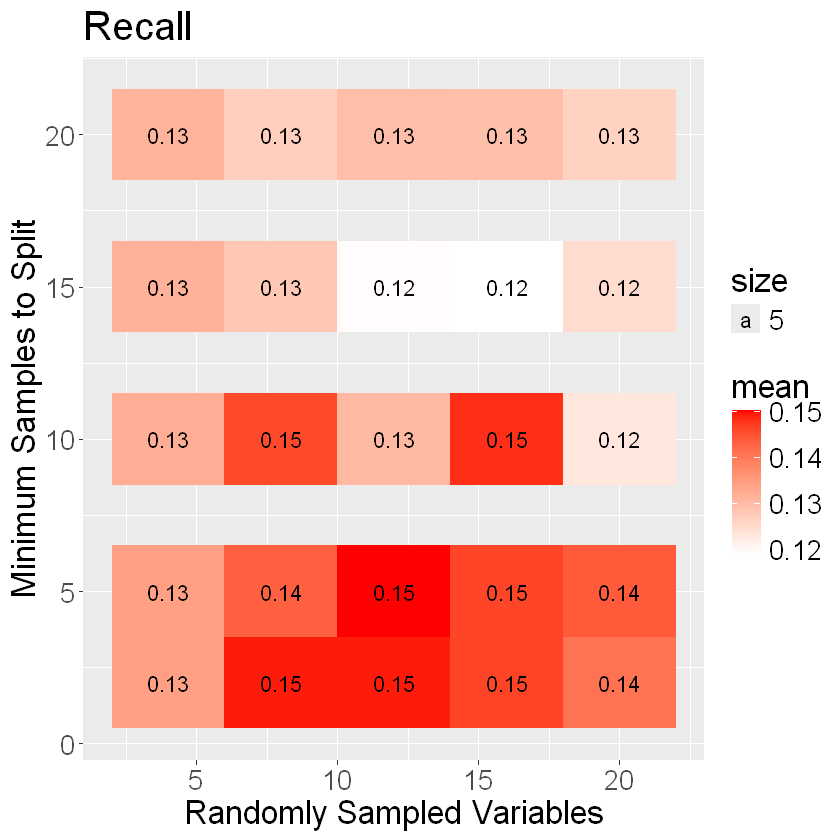

In [12]:
# plot accuracies of all values of hyperparameters

ggplot(model_tuning_accuracies %>% filter(.metric == "recall")) +
    geom_tile(aes(x=mtry, y=min_n, fill=mean)) +
    geom_text(aes(x=mtry, y=min_n, label=round(mean, 2), size=5)) +
    labs(x = "Randomly Sampled Variables", y = "Minimum Samples to Split", color="Estimated Recall", title="Recall") +
    theme(text = element_text(size=20)) +
    scale_fill_gradient(low="white", high="red")

# Print best hyperparameter values
best_params <- model_tuning_accuracies %>% arrange(desc(mean)) %>% head(1) %>% pull(mtry, min_n)
print("Best hyperparameters:")
print(best_params)

In [13]:
# retrain model on best parameters
best_params <- model_tuning %>%
  select_best()
print("Best Parameters:")
print(best_params)

model <- workflow() %>%
    add_recipe(recipe) %>%
    add_model(model_tuning_spec) %>%
    finalize_workflow(best_params) %>%
    # fit_resamples(resamples = train_vfold) # for v-fold cross validation
    fit(data = train_data) # to train on whole train set with no validation set

model

Warning message in select_best(.):
"No value of `metric` was given; "accuracy" will be used."


[1] "Best Parameters:"
# A tibble: 1 × 3
   mtry min_n .config         
  <dbl> <dbl> <chr>           
1     8     2 pre0_mod06_post0


Warning message:
"Dropped unused factor level(s) in dependent variable: 119."


══ Workflow [trained] ══════════════════════════════════════════════════════════
Preprocessor: Recipe
Model: rand_forest()

── Preprocessor ────────────────────────────────────────────────────────────────
2 Recipe Steps

• step_scale()
• step_center()

── Model ───────────────────────────────────────────────────────────────────────
Ranger result

Call:
 ranger::ranger(x = maybe_data_frame(x), y = y, mtry = min_cols(~8,      x), num.trees = ~1000, min.node.size = min_rows(~2, x), importance = ~"impurity",      num.threads = 1, verbose = FALSE, seed = sample.int(10^5,          1), probability = TRUE) 

Type:                             Probability estimation 
Number of trees:                  1000 
Sample size:                      296 
Number of independent variables:  24 
Mtry:                             8 
Target node size:                 2 
Variable importance mode:         impurity 
Splitrule:                        gini 
OOB prediction error (Brier s.):  0.7526137 

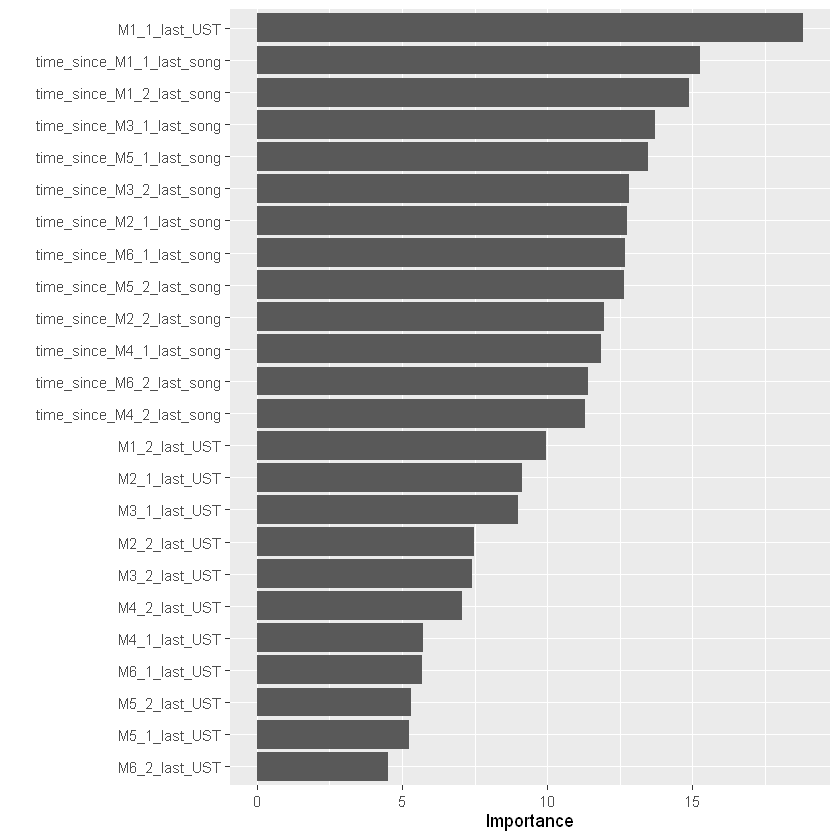

In [14]:
model %>% extract_fit_engine() %>% vip(num_features=50)

In [15]:
# Predict on the test set, and create a new DataFrame with inputs and outputs
test_predictions <- model %>% predict(test_data) %>%
    bind_cols(test_data)

In [16]:
# test_predictions

In [17]:
# What was the accuracy, precision, and recall of our model?
test_predictions %>% metrics(truth = UST, estimate = .pred_class)
test_predictions %>% precision(truth = UST, estimate = .pred_class, event_level = "second") # Precision = correct positive predictions / total positive predictions
test_predictions %>% recall(truth = UST, estimate = .pred_class, event_level = "second") # Recall = correct positive predictions / total positive test set observations

.metric,.estimator,.estimate
<chr>,<chr>,<dbl>
accuracy,multiclass,0.14615385
kap,multiclass,0.01542031


Warning message:
"While computing multiclass `precision()`, some levels had no predicted events
(i.e. `true_positive + false_positive = 0`).
Precision is undefined in this case, and those levels will be removed from the
averaged result.
Note that the following number of true events actually occurred for each
problematic event level:
'0': 0, '12': 0, '16': 0, '116': 2, '117': 1, '118': 0, '119': 1"


.metric,.estimator,.estimate
<chr>,<chr>,<dbl>
precision,macro,0.2325943


Warning message:
"While computing multiclass `recall()`, some levels had no true events (i.e.
`true_positive + false_negative = 0`).
Recall is undefined in this case, and those levels will be removed from the
averaged result.
Note that the following number of predicted events actually occurred for each
problematic event level:
'0': 0, '12': 0, '16': 0, '118': 0"


.metric,.estimator,.estimate
<chr>,<chr>,<dbl>
recall,macro,0.1050961


In [18]:
# test_predictions %>% pull(does_it_match) %>% levels()
confusion_matrix <- test_predictions %>%
    conf_mat(truth = UST, estimate = .pred_class)
confusion_matrix

          Truth
Prediction  0  3  5  8  9 10 12 13 16 17 21 29 116 117 118 119
       0    0  0  0  0  0  0  0  0  0  0  0  0   0   0   0   0
       3    0  3  1  4  7  5  0  3  0  3  2  5   0   1   0   0
       5    0  0  0  0  0  0  0  1  0  0  0  1   0   0   0   0
       8    0 12  1  3  7  1  0  1  0  2  2  2   0   0   0   1
       9    0  2  2  6  3  3  0  1  0  1  1  2   1   0   0   0
       10   0  0  0  2  3  4  0  1  0  1  1  3   0   0   0   0
       12   0  0  0  0  0  0  0  0  0  0  0  0   0   0   0   0
       13   0  0  0  0  0  0  0  1  0  0  0  0   0   0   0   0
       16   0  0  0  0  0  0  0  0  0  0  0  0   0   0   0   0
       17   0  0  0  0  0  0  0  0  0  0  0  0   1   0   0   0
       21   0  2  3  2  3  0  0  0  0  2  2  1   0   0   0   0
       29   0  1  0  0  0  2  0  1  0  1  0  3   0   0   0   0
       116  0  0  0  0  0  0  0  0  0  0  0  0   0   0   0   0
       117  0  0  0  0  0  0  0  0  0  0  0  0   0   0   0   0
       118  0  0  0  0  0  0  0  0  0  